# How it work: doing custom code without using keras

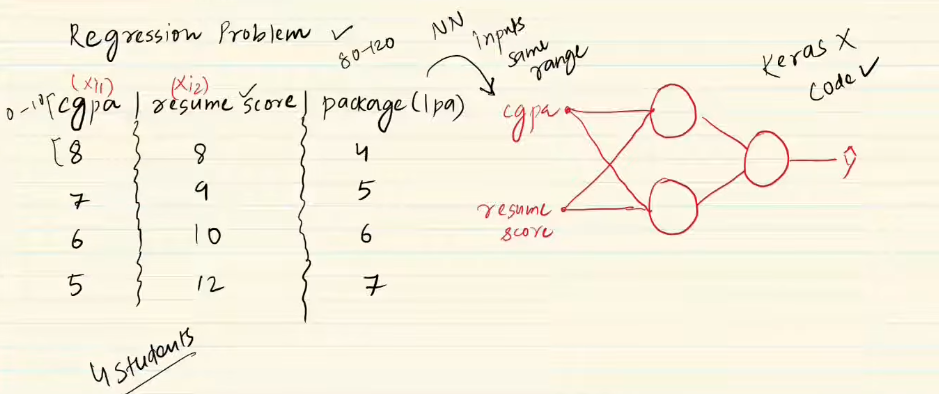

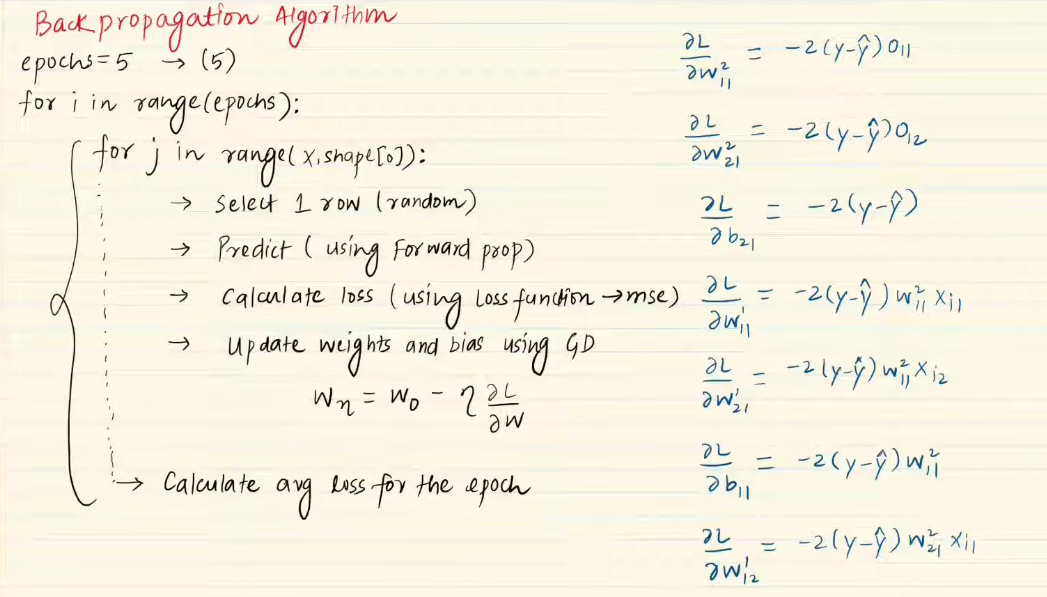

In [77]:
import numpy as np
import pandas as pd

In [78]:
df = pd.DataFrame([[8,8,4],[7,9,5],[6,10,6],[5,12,7]], columns=['cgpa', 'profile_score', 'lpa'])

In [79]:
df

,cgpa,profile_score,lpa
0,8,8,4
1,7,9,5
2,6,10,6
3,5,12,7


# initialize parameter
- eikhane neural network er architecture initailize korbo
- so, eikhane weight/w = 0.1
- and bias/b = 0

In [80]:
def initialize_parameters(layers_dims):
    
    np.random.seed(3)
    parameters = {}
    L = len(layers_dims)

    for l in range(1,L):
        parameters['W' + str(l)] = np.ones((layers_dims[l-1], layers_dims[l]))*0.1
        parameters['b' + str(l)] = np.zeros((layers_dims[l],1))

    return parameters

In [81]:
initialize_parameters([2,2,1])

{'W1': array([[0.1, 0.1],
        [0.1, 0.1]]),
 'b1': array([[0.],
        [0.]]),
 'W2': array([[0.1],
        [0.1]]),
 'b2': array([[0.]])}

# predict output using forward propagation

In [82]:
def linear_forward(A_prev, W, b):
    Z = np.dot(W.T, A_prev) + b

    return Z

# main forward propagation calculation

In [83]:
# Forward Prop
def L_layer_forward(X, parameters):

  A = X
  A_prev = X
  
  L = len(parameters) // 2                  # number of layers in the neural network
  
  for l in range(1, L+1):

    A_prev = A 
    
    Wl = parameters['W' + str(l)]
    bl = parameters['b' + str(l)]
    # print("A"+str(l-1)+": ", A_prev)
    # print("W"+str(l)+": ", Wl)
    # print("b"+str(l)+": ", bl)
    # print("--"*20)

    A = linear_forward(A_prev, Wl, bl)
    # print("A"+str(l)+": ", A)
    # print("**"*20)
          
  return A , A_prev

# outputs of first student

In [84]:
X = df[['cgpa', 'profile_score']].values[0].reshape(2,1) # Shape(no of features, no. of training example)
y = df[['lpa']].values[0][0]

# Parameter initialization
parameters = initialize_parameters([2,2,1])

y_hat,A1 = L_layer_forward(X,parameters)  
# L_layer_forward(X,parameters)
# y_hat = y_hat[0][0]

# # update_parameters(parameters,y,y_hat,A1,X)

# print('Loss for this student - ',-y*np.log(y_hat) - (1-y)*np.log(1-y_hat))

# # parameters
# L_layer_forward(X,parameters)

In [85]:
y_hat = y_hat[0][0]

In [86]:
A1

array([[1.6],
       [1.6]])

# calculate the loss

In [87]:
(y-0.32)**2

np.float64(13.5424)

# update the parameter using gradient descent mannually

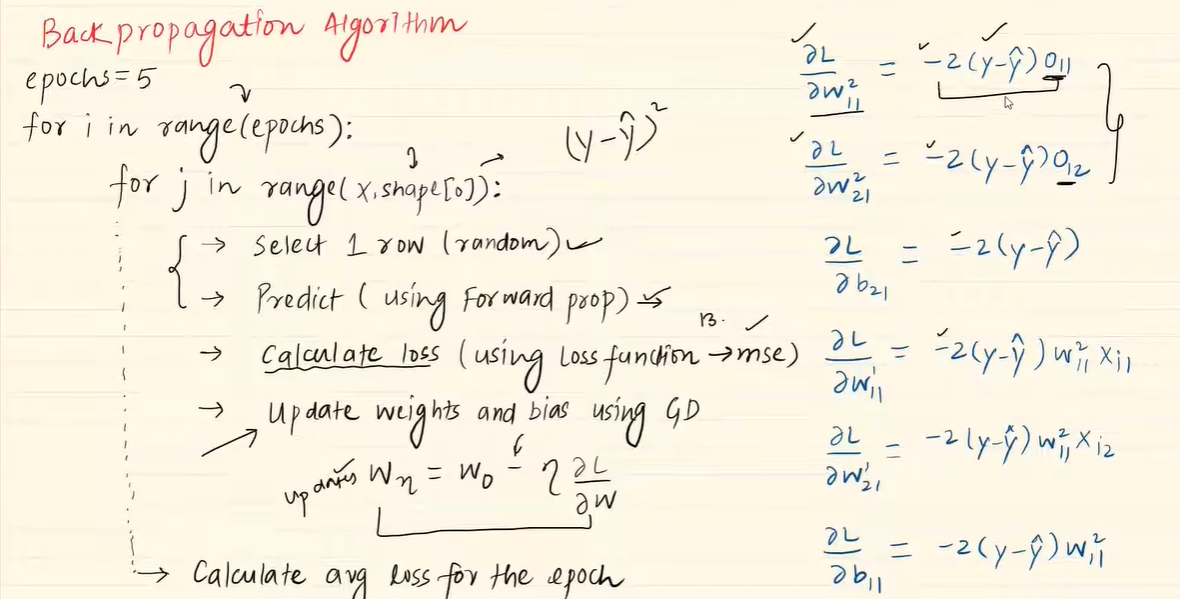

In [88]:
def update_parameters(parameters,y,y_hat,A1,X):
  parameters['W2'][0][0] = parameters['W2'][0][0] + (0.001 * 2 * (y - y_hat)*A1[0][0])
  parameters['W2'][1][0] = parameters['W2'][1][0] + (0.001 * 2 * (y - y_hat)*A1[1][0])
  parameters['b2'][0][0] = parameters['W2'][1][0] + (0.001 * 2 * (y - y_hat))

  parameters['W1'][0][0] = parameters['W1'][0][0] + (0.001 * 2 * (y - y_hat)*parameters['W2'][0][0]*X[0][0])
  parameters['W1'][0][1] = parameters['W1'][0][1] + (0.001 * 2 * (y - y_hat)*parameters['W2'][0][0]*X[1][0])
  parameters['b1'][0][0] = parameters['b1'][0][0] + (0.001 * 2 * (y - y_hat)*parameters['W2'][0][0])

  parameters['W1'][1][0] = parameters['W1'][1][0] + (0.001 * 2 * (y - y_hat)*parameters['W2'][1][0]*X[0][0])
  parameters['W1'][1][1] = parameters['W1'][1][1] + (0.001 * 2 * (y - y_hat)*parameters['W2'][1][0]*X[1][0])
  parameters['b1'][1][0] = parameters['b1'][1][0] + (0.001 * 2 * (y - y_hat)*parameters['W2'][1][0])

In [89]:
update_parameters(parameters,y,y_hat,A1,X)

In [90]:
parameters

{'W1': array([[0.10658137, 0.10658137],
        [0.10658137, 0.10658137]]),
 'b1': array([[0.00082267],
        [0.00082267]]),
 'W2': array([[0.111776],
        [0.111776]]),
 'b2': array([[0.119136]])}

# epoch implementation

In [92]:
# epochs implementation

parameters = initialize_parameters([2,2,1])
epochs = 10

for i in range(epochs):

  Loss = []

  for j in range(df.shape[0]):

    X = df[['cgpa', 'profile_score']].values[j].reshape(2,1) # Shape(no of features, no. of training example)
    y = df[['lpa']].values[j][0]

    # Parameter initialization


    y_hat,A1 = L_layer_forward(X,parameters)
    y_hat = y_hat[0][0]

    update_parameters(parameters,y,y_hat,A1,X)

    Loss.append((y-y_hat)**2)

  print('Epoch - ',i+1,'Loss - ',np.array(Loss).mean())

parameters

Epoch -  1 Loss -  25.321744156025517
Epoch -  2 Loss -  18.320004165722047
Epoch -  3 Loss -  9.473661050729628
Epoch -  4 Loss -  3.2520938634031613
Epoch -  5 Loss -  1.3407132589299962
Epoch -  6 Loss -  1.1726178458115697
Epoch -  7 Loss -  1.2331289135532644
Epoch -  8 Loss -  1.2686856723180788
Epoch -  9 Loss -  1.282007891421992
Epoch -  10 Loss -  1.2866806711744867


{'W1': array([[0.251385  , 0.42030991],
        [0.26250745, 0.45149331]]),
 'b1': array([[0.02847052],
        [0.03098528]]),
 'W2': array([[0.42075476],
        [0.49891207]]),
 'b2': array([[0.50135566]])}